# This is a sample Jupyter Notebook

Below is an example of a code cell. 
Put your cursor into the cell and press Shift+Enter to execute it and select the next one, or click 'Run Cell' button.

Press Double Shift to search everywhere for classes, files, tool windows, actions, and settings.

To learn more about Jupyter Notebooks in PyCharm, see [help](https://www.jetbrains.com/help/pycharm/ipython-notebook-support.html).
For an overview of PyCharm, go to Help -> Learn IDE features or refer to [our documentation](https://www.jetbrains.com/help/pycharm/getting-started.html).

In [37]:
import pandas as pd
from pandas._libs.tslibs import vectorized


In [ ]:
%%sql


In [38]:
df_train = pd.read_csv('../../data/social-media-extremism-detection-challenge/train.csv')
df_test =  pd.read_csv('../../data/social-media-extremism-detection-challenge/test.csv')

In [39]:
df_train.head()

,ID,Original_Message,Extremism_Label
0,1,sixth forms should burn to the ground,EXTREMIST
1,2,whatever should burn benders to the ground,EXTREMIST
2,3,factories should burn to the ground,EXTREMIST
3,4,halal factories should burn to the ground,EXTREMIST
4,5,nhs should burn to the ground,EXTREMIST


In [40]:
df_train.info()

<class 'pandas.DataFrame'>
RangeIndex: 2250 entries, 0 to 2249
Data columns (total 3 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   ID                2250 non-null   int64
 1   Original_Message  2249 non-null   str  
 2   Extremism_Label   2250 non-null   str  
dtypes: int64(1), str(2)
memory usage: 52.9 KB


In [120]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

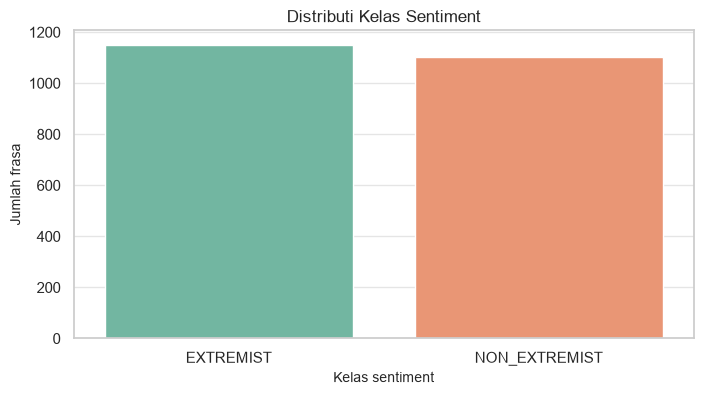

In [122]:
sns.set_theme(style='whitegrid')

plt.figure(figsize=(8, 4))
ax = sns.countplot(x='Extremism_Label', hue='Extremism_Label', data=df_train, palette= 'Set2')
plt.title('Distributi Kelas Sentiment', fontsize = 12)
plt.xlabel('Kelas sentiment', fontsize = 10)
plt.ylabel('Jumlah frasa', fontsize =10)

plt.show()


In [41]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [42]:
df_train.nunique()

ID                  2250
Original_Message    2249
Extremism_Label        2
dtype: int64

In [43]:
df_train['Extremism_Label'].value_counts()

Extremism_Label
EXTREMIST        1149
NON_EXTREMIST    1101
Name: count, dtype: int64

In [44]:
df_train = df_train.drop('ID', axis = 1)

In [45]:
df_train.info()

<class 'pandas.DataFrame'>
RangeIndex: 2250 entries, 0 to 2249
Data columns (total 2 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Original_Message  2249 non-null   str  
 1   Extremism_Label   2250 non-null   str  
dtypes: str(2)
memory usage: 35.3 KB


In [46]:
from sklearn.preprocessing import OneHotEncoder

In [47]:
df_encoded = pd.get_dummies(df_train, columns=['Extremism_Label'], dtype=int)

In [59]:
df_encoded = df_encoded.dropna()

In [60]:
df_encoded.info()

<class 'pandas.DataFrame'>
Index: 2249 entries, 0 to 2249
Data columns (total 3 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   Original_Message               2249 non-null   str  
 1   Extremism_Label_EXTREMIST      2249 non-null   int64
 2   Extremism_Label_NON_EXTREMIST  2249 non-null   int64
dtypes: int64(2), str(1)
memory usage: 70.3 KB


In [123]:
df_encoded.head()

,Original_Message,Extremism_Label_EXTREMIST,Extremism_Label_NON_EXTREMIST
0,sixth forms should burn to the ground,1,0
1,whatever should burn benders to the ground,1,0
2,factories should burn to the ground,1,0
3,halal factories should burn to the ground,1,0
4,nhs should burn to the ground,1,0


In [61]:
from sklearn.model_selection import train_test_split

In [62]:
X = df_encoded['Original_Message']
y = df_encoded[['Extremism_Label_EXTREMIST','Extremism_Label_NON_EXTREMIST']]

X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)

print(len(X_train))
print(len(y_train))
print(len(X_val))
print(len(y_val))

1799
1799
450
450


In [63]:
from sklearn.feature_extraction.text import TfidfVectorizer

In [72]:
from sklearn.multioutput import MultiOutputClassifier

In [73]:
vectorized = TfidfVectorizer(
    max_features=1500,
    ngram_range=(1, 2),
    stop_words='english',
)

X_train_vec = vectorized.fit_transform(X_train)
X_val_vec = vectorized.transform(X_val)


In [74]:
from sklearn.linear_model import LogisticRegression

In [75]:
base_model = LogisticRegression(
    max_iter=1000,
    C=1.0,
    class_weight='balanced',
    random_state=42,
)

model = MultiOutputClassifier(base_model)

model.fit(X_train_vec, y_train)

,estimator estimator: estimator objectAn estimator object implementing :term:`fit` and :term:`predict`.A :term:`predict_proba` method will be exposed only if `estimator` implementsit.,LogisticRegre...ndom_state=42)
,"n_jobs n_jobs: int or None, optional (default=None)The number of jobs to run in parallel.:meth:`fit`, :meth:`predict` and :meth:`partial_fit` (if supportedby the passed estimator) will be parallelized for each target.When individual estimators are fast to train or predict,using ``n_jobs > 1`` can result in slower performance dueto the parallelism overhead.``None`` means `1` unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all available processes / threads.See :term:`Glossary <n_jobs>` for more details... versionchanged:: 0.20 `n_jobs` default changed from `1` to `None`.",None
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)Class labels.",list,"[array([0, 1]), array([0, 1])]"
estimators_ estimators_: list of ``n_output`` estimatorsEstimators used for predictions.,list,"[LogisticRegre...ndom_state=42), LogisticRegre...ndom_state=42)]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying `estimator` exposes such an attribute when fit... versionadded:: 0.24,int,1500
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0


In [95]:
from sklearn.metrics import accuracy_score, classification_report, f1_score

In [97]:
y_pred = model.predict(X_val_vec)

accuracy = accuracy_score(y_val, y_pred)
#f1_score = f1_score(y_val, y_pred)
print(accuracy)

0.8088888888888889


In [98]:
from sklearn.ensemble import RandomForestClassifier

In [99]:
base_model = RandomForestClassifier(
    n_estimators=1000,
    class_weight='balanced',
    random_state=42,
)

model = MultiOutputClassifier(base_model)

model.fit(X_train_vec, y_train)

,estimator estimator: estimator objectAn estimator object implementing :term:`fit` and :term:`predict`.A :term:`predict_proba` method will be exposed only if `estimator` implementsit.,RandomForestC...ndom_state=42)
,"n_jobs n_jobs: int or None, optional (default=None)The number of jobs to run in parallel.:meth:`fit`, :meth:`predict` and :meth:`partial_fit` (if supportedby the passed estimator) will be parallelized for each target.When individual estimators are fast to train or predict,using ``n_jobs > 1`` can result in slower performance dueto the parallelism overhead.``None`` means `1` unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all available processes / threads.See :term:`Glossary <n_jobs>` for more details... versionchanged:: 0.20 `n_jobs` default changed from `1` to `None`.",None
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)Class labels.",list,"[array([0, 1]), array([0, 1])]"
estimators_ estimators_: list of ``n_output`` estimatorsEstimators used for predictions.,list,"[RandomForestC...ndom_state=42), RandomForestC...ndom_state=42)]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying `estimator` exposes such an attribute when fit... versionadded:: 0.24,int,1500
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",1000
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None


In [86]:
y_pred = model.predict(X_val_vec)

accuracy = accuracy_score(y_val, y_pred)
print(accuracy)

0.8133333333333334


In [92]:
from sklearn.ensemble import GradientBoostingClassifier
base_model = GradientBoostingClassifier(
    n_estimators=100,
    random_state=42,
)

model = MultiOutputClassifier(base_model)

model.fit(X_train_vec, y_train)

,estimator estimator: estimator objectAn estimator object implementing :term:`fit` and :term:`predict`.A :term:`predict_proba` method will be exposed only if `estimator` implementsit.,GradientBoost...ndom_state=42)
,"n_jobs n_jobs: int or None, optional (default=None)The number of jobs to run in parallel.:meth:`fit`, :meth:`predict` and :meth:`partial_fit` (if supportedby the passed estimator) will be parallelized for each target.When individual estimators are fast to train or predict,using ``n_jobs > 1`` can result in slower performance dueto the parallelism overhead.``None`` means `1` unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all available processes / threads.See :term:`Glossary <n_jobs>` for more details... versionchanged:: 0.20 `n_jobs` default changed from `1` to `None`.",None
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)Class labels.",list,"[array([0, 1]), array([0, 1])]"
estimators_ estimators_: list of ``n_output`` estimatorsEstimators used for predictions.,list,"[GradientBoost...ndom_state=42), GradientBoost...ndom_state=42)]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying `estimator` exposes such an attribute when fit... versionadded:: 0.24,int,1500
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to each Tree estimator at eachboosting iteration.In addition, it controls the random permutation of the features ateach split (see Notes for more details).It also controls the random splitting of the training data to obtain avalidation set if `n_iter_no_change` is not None.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"loss loss: {'log_loss', 'exponential'}, default='log_loss'The loss function to be optimized. 'log_loss' refers to binomial andmultinomial deviance, the same as used in logistic regression.It is a good choice for classification with probabilistic outputs.For loss 'exponential', gradient boosting recovers the AdaBoost algorithm.",'log_loss'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.For an example of the effects of this parameter and its interaction with``subsample``, see:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_regularization.py`.",0.1
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",100
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0


In [93]:
y_pred = model.predict(X_val_vec)

accuracy = accuracy_score(y_val, y_pred)
print(accuracy)

0.8088888888888889


Subsmission

In [107]:
X_full_vec = vectorized.fit_transform(df_encoded['Original_Message'])
y_full = df_encoded[['Extremism_Label_EXTREMIST', 'Extremism_Label_NON_EXTREMIST']]

In [108]:
final_model = RandomForestClassifier(
    n_estimators=1000,
    class_weight='balanced',
    random_state=42,
)

fin_model = MultiOutputClassifier(final_model)

fin_model.fit(X_full_vec, y_full)

,estimator estimator: estimator objectAn estimator object implementing :term:`fit` and :term:`predict`.A :term:`predict_proba` method will be exposed only if `estimator` implementsit.,RandomForestC...ndom_state=42)
,"n_jobs n_jobs: int or None, optional (default=None)The number of jobs to run in parallel.:meth:`fit`, :meth:`predict` and :meth:`partial_fit` (if supportedby the passed estimator) will be parallelized for each target.When individual estimators are fast to train or predict,using ``n_jobs > 1`` can result in slower performance dueto the parallelism overhead.``None`` means `1` unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all available processes / threads.See :term:`Glossary <n_jobs>` for more details... versionchanged:: 0.20 `n_jobs` default changed from `1` to `None`.",None
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)Class labels.",list,"[array([0, 1]), array([0, 1])]"
estimators_ estimators_: list of ``n_output`` estimatorsEstimators used for predictions.,list,"[RandomForestC...ndom_state=42), RandomForestC...ndom_state=42)]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying `estimator` exposes such an attribute when fit... versionadded:: 0.24,int,1500
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",1000
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None


In [110]:
df_test.info()

<class 'pandas.DataFrame'>
RangeIndex: 750 entries, 0 to 749
Data columns (total 2 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   ID                750 non-null    int64
 1   Original_Message  750 non-null    str  
dtypes: int64(1), str(1)
memory usage: 11.8 KB


In [115]:
X_test_vec = vectorized.transform(df_test['Original_Message'])
test_pred = fin_model.predict(X_test_vec)

submission = pd.DataFrame({
    'ID': df_test['ID'],
    'target': test_pred[:, 0]}
)

submission.to_csv('submission.csv', index=False)
submission.head()

,ID,target
0,2251,0
1,2252,0
2,2253,0
3,2254,0
4,2255,0
